# O que o meu diário de estágio mostra

Análise em Python (pandas + matplotlib) dos dias registrados no relatório de estágio.

> **Os dados são fictícios.** São os mesmos da [demo do relatório](https://adnactorres.github.io/relatorio-estagio-demo/): nomes, clientes e situações foram inventados, mas imitam a rotina real de uma estagiária de QA. A ideia aqui é mostrar o raciocínio, não tirar conclusões sobre uma empresa.

**Perguntas que eu quis responder:**
1. Como o meu tempo se dividiu entre os tipos de atividade?
2. Em quais times e clientes eu mais trabalhei?
3. Onde apareceram mais erros, considerando quanto tempo passei em cada cliente?
4. Os erros mudaram ao longo das semanas?
5. Que tipo de erro eu mais encontro?

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

import diario as D

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10.5, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": D.LINHA, "axes.labelcolor": D.CINZA, "xtick.color": D.CINZA, "ytick.color": D.CINZA,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
})
GRAFICOS = Path("graficos"); GRAFICOS.mkdir(exist_ok=True)
def salvar(fig, nome):
    fig.savefig(GRAFICOS / f"{nome}.png", bbox_inches="tight", facecolor="white")

bruto = D.carregar()
dias = D.tabela_dias(bruto)
erros = D.tabela_erros(bruto)
dias.head()

,data,time,clientes,tipos,atividades,erros,melhorias,pendencias,mes,semana
0,2026-09-29,Onboarding,[],"[Treinamento, Administrativo]",2,0,0,0,2026-09,2026-09-28
1,2026-09-30,Onboarding,[],"[Treinamento, Administrativo]",2,0,0,0,2026-09,2026-09-28
2,2026-10-01,Onboarding,[],[Treinamento],2,0,0,0,2026-10,2026-09-28
3,2026-10-02,Onboarding,[],"[Treinamento, Reuniões]",2,0,0,0,2026-10,2026-09-28
4,2026-10-05,Onboarding,[],[Treinamento],2,0,0,0,2026-10,2026-10-05


## Visão geral

In [2]:
resumo = pd.Series({
    "Dias registrados": len(dias),
    "Período": f"{dias.data.min():%d/%m/%Y} a {dias.data.max():%d/%m/%Y}",
    "Atividades registradas": dias.atividades.sum(),
    "Erros encontrados": dias.erros.sum(),
    "Melhorias sugeridas": dias.melhorias.sum(),
    "Dias com pendência ou bloqueio": (dias.pendencias > 0).sum(),
})
resumo.to_frame("valor")

,valor
Dias registrados,35
Período,29/09/2026 a 17/11/2026
Atividades registradas,75
Erros encontrados,9
Melhorias sugeridas,7
Dias com pendência ou bloqueio,4


## 1. Como o meu tempo se dividiu

Cada dia pode ter mais de um tipo de atividade, então a conta é **em quantos dias** cada tipo aparece.

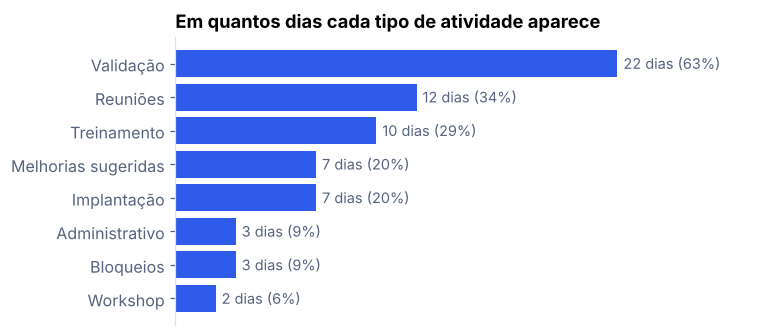

In [3]:
tipos = D.explodir(dias, "tipos")["tipos"].value_counts()
pct = (tipos / len(dias) * 100).round()

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.barh(tipos.index[::-1], tipos.values[::-1], color=D.AZUL)
for i, (n, p) in enumerate(zip(tipos.values[::-1], pct.values[::-1])):
    ax.text(n + 0.3, i, f"{n} dias ({p:.0f}%)", va="center", color=D.CINZA, fontsize=9.5)
ax.set_title("Em quantos dias cada tipo de atividade aparece")
ax.set_xlim(0, tipos.max() * 1.35); ax.xaxis.set_visible(False); ax.spines["bottom"].set_visible(False)
salvar(fig, "1-tipos-de-atividade"); plt.show()

## 2. Times e clientes

In [4]:
por_time = dias.groupby("time", sort=False).agg(dias=("data", "size"), erros=("erros", "sum"), melhorias=("melhorias", "sum"))
por_time

,dias,erros,melhorias
time,,,
Onboarding,6,0,0
Customização,21,8,5
Implantação,8,1,2


In [5]:
cli = D.explodir(dias, "clientes")
dias_cliente = cli.groupby("clientes").size().rename("dias")
erros_cliente = erros.groupby("cliente").size().rename("erros")
clientes = pd.concat([dias_cliente, erros_cliente], axis=1).fillna(0).astype(int).sort_values("dias", ascending=False)
clientes["erros por dia"] = (clientes.erros / clientes.dias).round(2)
clientes

,dias,erros,erros por dia
UFVS,12,7,0.58
UESM,9,1,0.11
UFPN,4,1,0.25
UERA,3,0,0.00
UECV,2,0,0.00


## 3. Onde aparecem mais erros

Comparar só o total de erros engana: um cliente em que passei mais dias tende a ter mais erros. Por isso olho também **erros por dia trabalhado** naquele cliente.

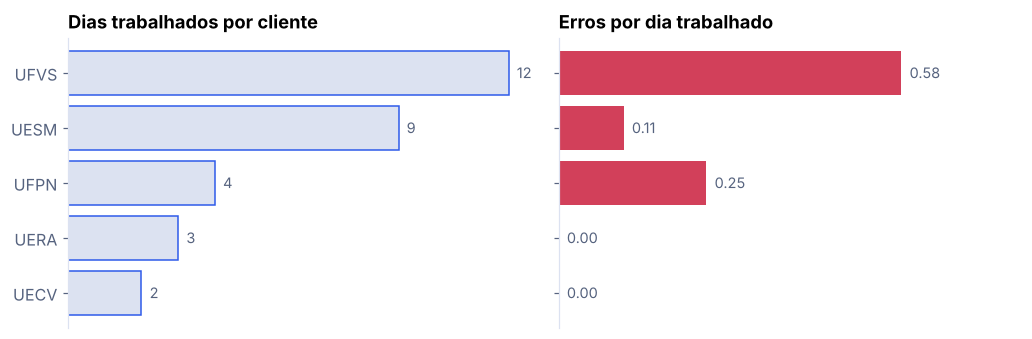

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(9.5, 3.2), sharey=True)
ordem = clientes.index[::-1]
axs[0].barh(ordem, clientes.loc[ordem, "dias"], color=D.LINHA, edgecolor=D.AZUL)
axs[0].set_title("Dias trabalhados por cliente")
axs[1].barh(ordem, clientes.loc[ordem, "erros por dia"], color=D.VERMELHO)
axs[1].set_title("Erros por dia trabalhado")
for ax, col, fmt in [(axs[0], "dias", "{:.0f}"), (axs[1], "erros por dia", "{:.2f}")]:
    for i, v in enumerate(clientes.loc[ordem, col]):
        ax.text(v, i, "  " + fmt.format(v), va="center", color=D.CINZA, fontsize=9.5)
    ax.xaxis.set_visible(False); ax.spines["bottom"].set_visible(False)
axs[1].set_xlim(0, clientes["erros por dia"].max() * 1.35)
fig.tight_layout(); salvar(fig, "3-erros-por-cliente"); plt.show()

## 4. Ao longo das semanas

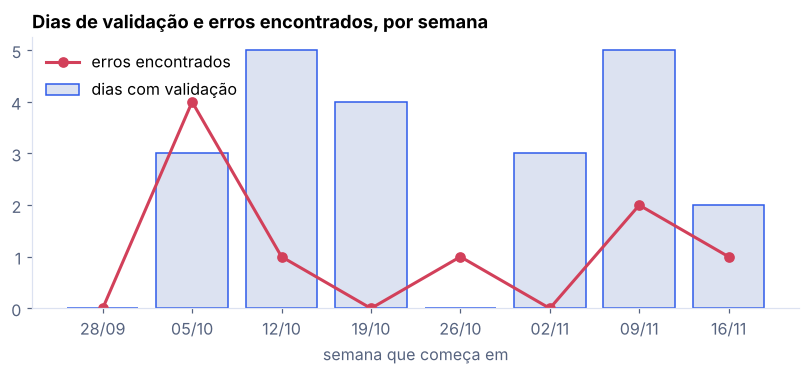

,dias,validacao,erros
semana,,,
2026-09-28,4,0,0
2026-10-05,5,3,4
2026-10-12,5,5,1
2026-10-19,5,4,0
2026-10-26,4,0,1
2026-11-02,5,3,0
2026-11-09,5,5,2
2026-11-16,2,2,1


In [7]:
semanas = dias.groupby("semana").agg(
    dias=("data", "size"),
    validacao=("tipos", lambda s: sum("Validação" in t for t in s)),
    erros=("erros", "sum"),
)
fig, ax = plt.subplots(figsize=(9, 3.2))
x = range(len(semanas))
ax.bar(x, semanas.validacao, color=D.LINHA, edgecolor=D.AZUL, label="dias com validação")
ax.plot(x, semanas.erros, color=D.VERMELHO, marker="o", linewidth=2, label="erros encontrados")
ax.set_xticks(list(x), [f"{s:%d/%m}" for s in semanas.index])
ax.set_title("Dias de validação e erros encontrados, por semana")
ax.set_xlabel("semana que começa em"); ax.legend(frameon=False, loc="upper left")
salvar(fig, "4-erros-por-semana"); plt.show()
semanas

## 5. Que tipo de erro eu mais encontro

Para agrupar os erros, usei regras simples de palavras-chave (estão em `diario.py`, na função `categorizar_erro`). É uma classificação rústica, mas fácil de explicar e de testar.

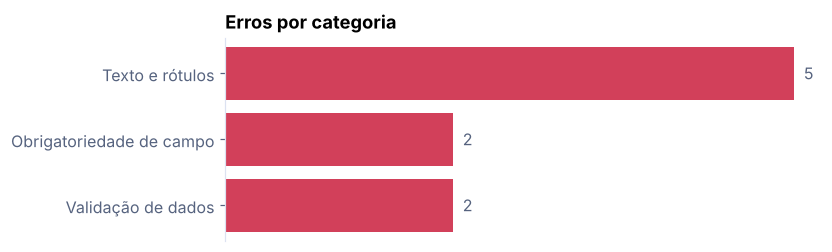

,data,cliente,categoria,erro
2,2026-10-09,UFVS,Obrigatoriedade de campo,Campo marcado como obrigatório que deveria ser...
4,2026-10-14,UFVS,Obrigatoriedade de campo,Cadastro aceito com o campo de documento em br...
0,2026-10-09,UFVS,Texto e rótulos,Legenda do ícone de campo obrigatório ausente ...
1,2026-10-09,UFVS,Texto e rótulos,Frase de confirmação diferente da especificada...
5,2026-10-29,UFPN,Texto e rótulos,Comprovante gerado com o nome de outra institu...
7,2026-11-11,UESM,Texto e rótulos,"Uso de ""CPF's"" no título de dois relatórios."
8,2026-11-17,UFVS,Texto e rótulos,Título do relatório de convocados aparece como...
3,2026-10-09,UFVS,Validação de dados,Número de matrícula negativo aceito no cadastro.
6,2026-11-09,UFVS,Validação de dados,Identificador de currículo duplicado aceito no...


In [8]:
cat = erros.categoria.value_counts()
fig, ax = plt.subplots(figsize=(7, 2.4))
ax.barh(cat.index[::-1], cat.values[::-1], color=D.VERMELHO)
for i, v in enumerate(cat.values[::-1]):
    ax.text(v + 0.05, i, f" {v}", va="center", color=D.CINZA)
ax.set_title("Erros por categoria"); ax.xaxis.set_visible(False); ax.spines["bottom"].set_visible(False)
salvar(fig, "5-categorias-de-erro"); plt.show()
erros[["data", "cliente", "categoria", "erro"]].sort_values("categoria")

In [9]:
# Para uma tabela de conclusões calculada direto dos dados
top_tipo = tipos.index[0]
cli_mais_dias = clientes.index[0]
cli_mais_erros_dia = clientes["erros por dia"].idxmax()
print(f"Tipo de atividade mais frequente: {top_tipo} ({pct[top_tipo]:.0f}% dos dias)")
print(f"Cliente com mais dias: {cli_mais_dias} ({clientes.loc[cli_mais_dias, 'dias']} dias)")
print(f"Cliente com mais erros por dia: {cli_mais_erros_dia} ({clientes.loc[cli_mais_erros_dia, 'erros por dia']:.2f})")
print(f"Categoria de erro mais comum: {cat.index[0]} ({cat.iloc[0]} de {cat.sum()})")

Tipo de atividade mais frequente: Validação (63% dos dias)
Cliente com mais dias: UFVS (12 dias)
Cliente com mais erros por dia: UFVS (0.58)
Categoria de erro mais comum: Texto e rótulos (5 de 9)


## O que eu levo disso

- **Validar é o centro do meu trabalho.** Validação aparece em 63% dos dias, quase o dobro de reuniões (34%). Faz sentido para QA, e confirma que o tempo de treinamento ficou concentrado no começo.
- **A customização concentrou quase tudo.** Foram 21 dos 35 dias e 8 dos 9 erros. Implantação e onboarding têm outro ritmo: menos telas novas para validar.
- **Olhar só o total de erros engana.** A UFVS tem mais dias *e* mais erros por dia trabalhado (0,58, contra 0,11 da UESM). É um sinal para revisar essa OS com mais cuidado, ou montar um checklist próprio para ela.
- **Os erros aparecem mais quando as telas são novas.** O pico foi na primeira semana de validação (4 erros), depois caiu. Também apareceu um erro numa semana sem validação formal, durante a implantação: erro não espera a fase de testes.
- **Mais da metade dos erros é de texto e rótulos** (5 de 9): títulos trocados, frases diferentes do documento, legenda faltando. É o tipo de verificação que dá para transformar em checklist ou automatizar, comparando os textos da tela com a especificação.

### Limites desta análise

- Os dados são fictícios e poucos: 35 dias e 9 erros. Servem para mostrar o método, não para afirmar tendências.
- A categorização usa regras de palavras-chave. Funciona bem para poucos erros, mas erra fácil quando a descrição muda de forma.

### Próximos passos

- Testar `categorizar_erro` com **pytest**, incluindo descrições estranhas de propósito.
- Classificar os erros com **IA** e comparar com as regras: onde as duas concordam e onde discordam.